# A tour of the k-space digital twin

An MRI scanner never takes a photo: it measures **k-space**, and the image is computed from it. This notebook walks through the twin step by step. Every picture is computed live by the code in `twin/`.

Run it top to bottom; the last cell has sliders to play with.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np

from twin.artifacts import motion, motion_rows, undersample_ky
from twin.contrast import TISSUES, param_maps, se_signal
from twin.experiments import grating, split_low_high
from twin.kspace import fft2c, ifft2c, log_mag
from twin.metrics import brain_mask, nrmse
from twin.sequences import acquire, multi_echo, scan_time, t2_map, tse_kspace

plt.rcParams.update({"figure.figsize": (12, 4), "image.cmap": "gray", "axes.titlesize": 12})


def show(*panels):
    fig, axs = plt.subplots(1, len(panels), figsize=(4 * len(panels), 4))
    for ax, (image, title, *cmap) in zip(np.atleast_1d(axs), panels):
        ax.imshow(image, cmap=cmap[0] if cmap else "gray")
        ax.set_title(title)
        ax.axis("off")
    plt.show()

## 1. One k-space point is one stripe pattern

An image made of a single stripe pattern has an almost empty k-space: one dot for its average brightness at the centre, and a mirror pair of dots at a distance equal to the number of stripes.

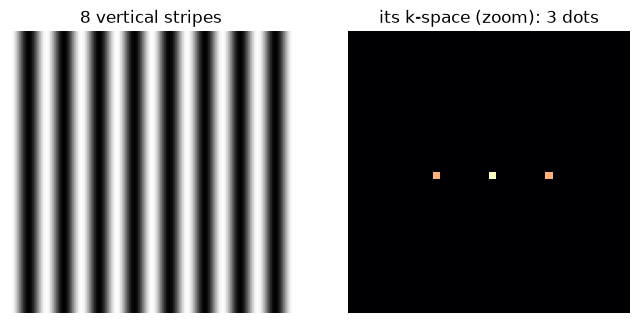

In [2]:
g = grating(n=128, cycles=8)
show((g, "8 vertical stripes"), (log_mag(fft2c(g))[44:84, 44:84], "its k-space (zoom): 3 dots", "magma"))

## 2. A brain made of real anatomy

The anatomy comes from the BrainWeb digital phantom (one slice, 12 tissue labels). Each tissue gets T1, T2 and proton density, and the spin-echo equation gives the brightness:

$$S = PD \,(1 - e^{-TR/T1})\, e^{-TE/T2}$$

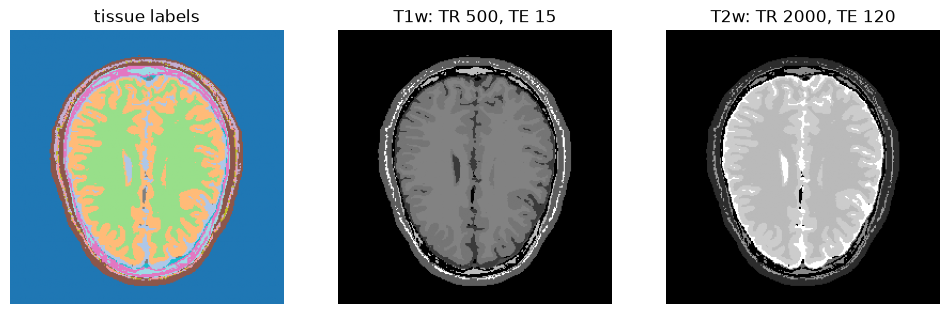

white matter  T1   785 ms   T2   90 ms   from course: ('t1', 't2')
grey matter   T1   920 ms   T2  100 ms   from course: ('t1', 't2')
CSF           T1  3000 ms   T2  200 ms   from course: ('t1', 't2')


In [3]:
labels = np.load(ROOT / "data/derived/brainweb_z200_labels_256.npy")
maps = param_maps(labels)


def se(tr, te):
    return se_signal(maps["pd"], maps["t1"], maps["t2"], tr, te)


show((labels, "tissue labels", "tab20"), (se(500, 15), "T1w: TR 500, TE 15"), (se(2000, 120), "T2w: TR 2000, TE 120"))
for name in ("white matter", "grey matter", "CSF"):
    t = TISSUES[name]
    print(f"{name:13s} T1 {t['t1']:>5} ms   T2 {t['t2']:>4} ms   from course: {t['course']}")

## 3. Centre = contrast, edges = detail

Keeping only the centre of k-space gives a blurry image with the right contrast. Keeping only the edges gives outlines. Together they give back the image exactly.

low + high = image, max error: 2.793896443884581e-16


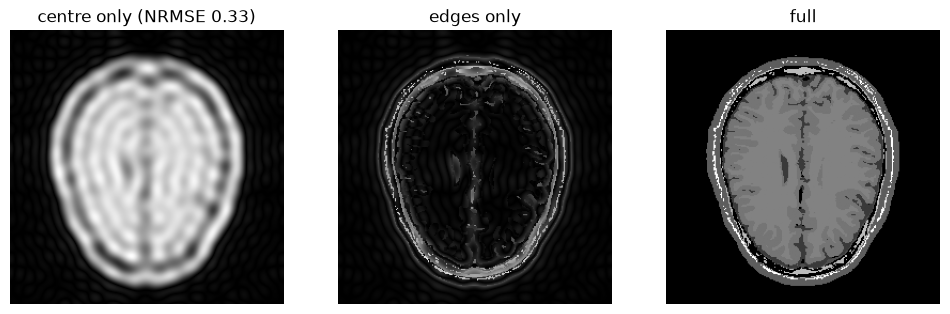

In [4]:
t1w = se(500, 15)
low, high = split_low_high(t1w, 16)
print("low + high = image, max error:", np.abs(low + high - t1w).max())
show((np.abs(low), f"centre only (NRMSE {nrmse(np.abs(low), t1w):.2f})"), (np.abs(high), "edges only"), (t1w, "full"))

## 4. Filling order and scan time

A spin echo measures one row per TR. Stopped after 10 % of the rows, a top-to-bottom scan has nothing useful yet, while a centre-out scan already shows the brain.

full scan: 128 s; stopped after 26 rows: 13 s


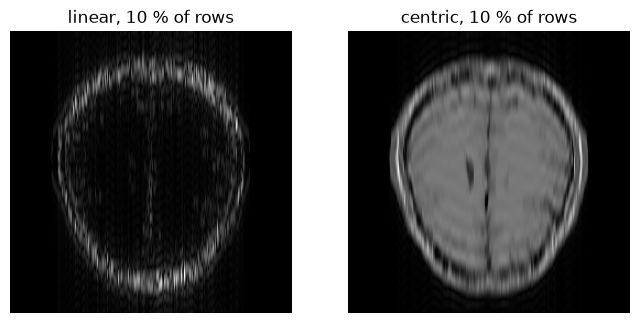

In [5]:
print(f"full scan: {scan_time(500, 256):.0f} s; stopped after 26 rows: {scan_time(500, 26):.0f} s")
show(*[(np.abs(ifft2c(acquire(t1w, kind, 26))), f"{kind}, 10 % of rows") for kind in ("linear", "centric")])

## 5. Turbo spin echo and the T2 map

A turbo spin echo fills several rows per TR, so the scan is ETL times faster. The echo at the centre of k-space sets the contrast. A multi-echo acquisition fitted pixel by pixel gives T2 in milliseconds.

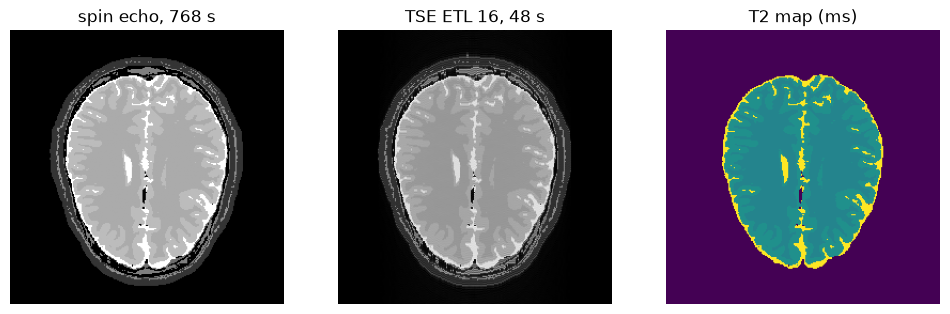

{'CSF': 199.99999999999991, 'GM': 100.0, 'WM': 90.00000000000003}


In [6]:
ref = se(3000, 100)
tse = np.abs(ifft2c(tse_kspace(maps, 3000, 16, 10, 100)))
tes = np.arange(20, 161, 20)
echoes = multi_echo(maps, 3000, tes)
mask = brain_mask(echoes[0]) & np.isin(labels, [1, 2, 3])
t2 = t2_map(echoes, tes, mask)
show((ref, f"spin echo, {scan_time(3000, 256):.0f} s"), (tse, f"TSE ETL 16, {scan_time(3000, 16):.0f} s"),
     (np.where(mask, t2, 0), "T2 map (ms)", "viridis"))
print({n: float(np.nanmedian(t2[labels == k])) for k, n in [(1, "CSF"), (2, "GM"), (3, "WM")]})

## 6. Artefacts come from k-space

Skipping every other row halves the field of view, so the head folds onto itself. Motion during some rows creates ghosts, always along the phase-encode (vertical) direction.

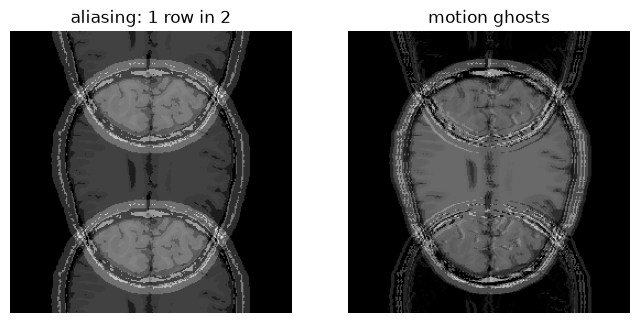

In [7]:
show((np.abs(ifft2c(undersample_ky(fft2c(t1w), 2))), "aliasing: 1 row in 2"),
     (np.abs(ifft2c(motion(t1w, (0, 3), motion_rows(256, "alternate")))), "motion ghosts"))

## 7. Play with TR and TE

Move the sliders (needs `ipywidgets`, and a live Jupyter kernel).

In [8]:
from ipywidgets import IntSlider, interact


@interact(tr=IntSlider(500, 100, 5000, 50, description="TR (ms)"), te=IntSlider(15, 5, 250, 5, description="TE (ms)"))
def contrast(tr, te):
    image = se(tr, te)
    show((image, f"TR {tr} ms, TE {te} ms"), (log_mag(fft2c(image)), "k-space", "magma"))

interactive(children=(IntSlider(value=500, description='TR (ms)', max=5000, min=100, step=50), IntSlider(value…

## Limits

The anatomy is real but the contrast is simulated: flat tissues, no noise unless added, magnitude images only (so the k-space is perfectly symmetric, unlike real data), some placeholder tissue values, idealised sequences. See `VALIDATION.md` for all the checks and the full list.